# Batch B · Frozen LEGAL-BERT and lexical comparison

The run uses the user's assumption that supplied labels have been reviewed. Family assignments retain their provisional status. All scores use the same 2021–2022 development cases. Parameters are selected on MASKED training folds.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
RUN = Path('.')
read = lambda name: json.loads((RUN / name).read_text())
run = read('run.json')
splits = pd.read_csv(RUN / 'splits.csv')
display(pd.crosstab(splits['period'], splits['label']))
display(run['release'])

label,0,1
period,,
train,64,33
validation,12,3


{'status': 'user_assumed_labels_reviewed',
 'dataset_version': 'batch_b/provisional_v1/B_development_v2_PROVISIONAL',
 'split_version': 'supplied 2010–2020 training / 2021–2022 validation',
 'label_field': 'draft_label_if_unanimous_include',
 'label_review_assumption': 'User instructed: Proceed, assuming the labels have been reviewed',
 'source_adjudication_statuses': ['pending_human_review'],
 'family_review_statuses': ['NOT_APPROVED'],
 'scope': 'Batch B only; same supplied development IDs for FULL and MASKED',
 'inputs': {'development': {'repository_path': 'annotation/submissions/hyunsang/preprocessing/batch_b/provisional_v1/B_development_v2_PROVISIONAL.jsonl',
   'sha256': '94e81d81d9e59a80d62df19d55862ff03b8539c26bb4eae3371c30340bb6cd21'},
  'labels': {'repository_path': 'annotation/submissions/hyunsang/preprocessing/batch_b/provisional_v1/inputs/B_three_reviewer_audit_169.csv',
   'sha256': '73c623eca3b67fae4c2662db8ba8a6a33581b2c8f82864c1d9f633252d5dd8f5'},
  'families': {'repos

## MASKED training selection

Three family-grouped folds within 2010–2020. Mean balanced accuracy determines C, then macro F1 and smaller C break ties. Each model uses its selected C for both variants.

In [2]:
selection = read('selection.json')
display(pd.DataFrame([dict(model=name, C=t['C'], balanced_accuracy=t['balanced_accuracy'], macro_f1=t['macro_f1'], selected=t['C']==result['selected_C']) for name,result in selection.items() for t in result['grid']]))

,model,C,balanced_accuracy,macro_f1,selected
0,TFIDF_LR,0.1,0.569625,0.548607,False
1,TFIDF_LR,1.0,0.571429,0.566825,False
2,TFIDF_LR,10.0,0.586941,0.581590,True
3,TFIDF_SVM,0.1,0.571429,0.566825,False
4,TFIDF_SVM,1.0,0.594517,0.589570,True
5,TFIDF_SVM,10.0,0.580087,0.579123,False
6,LEGAL_BERT_LR,0.1,0.554113,0.530945,True
7,LEGAL_BERT_LR,1.0,0.539322,0.519038,False
8,LEGAL_BERT_LR,10.0,0.524170,0.508243,False


## Shared development results

,model,variant,C,n,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1
0,Majority,FULL,NaN,15,0.800000,0.500000,0.444444,1.000000,0.000000
1,Majority,MASKED,NaN,15,0.800000,0.500000,0.444444,1.000000,0.000000
2,TFIDF_LR,FULL,10.0,15,0.800000,0.625000,0.640000,0.916667,0.333333
3,TFIDF_LR,MASKED,10.0,15,0.800000,0.500000,0.444444,1.000000,0.000000
4,TFIDF_SVM,FULL,1.0,15,0.800000,0.625000,0.640000,0.916667,0.333333
5,TFIDF_SVM,MASKED,1.0,15,0.733333,0.458333,0.423077,0.916667,0.000000
6,LEGAL_BERT_LR,FULL,0.1,15,0.733333,0.708333,0.659091,0.750000,0.666667
7,LEGAL_BERT_LR,MASKED,0.1,15,0.666667,0.666667,0.603175,0.666667,0.666667


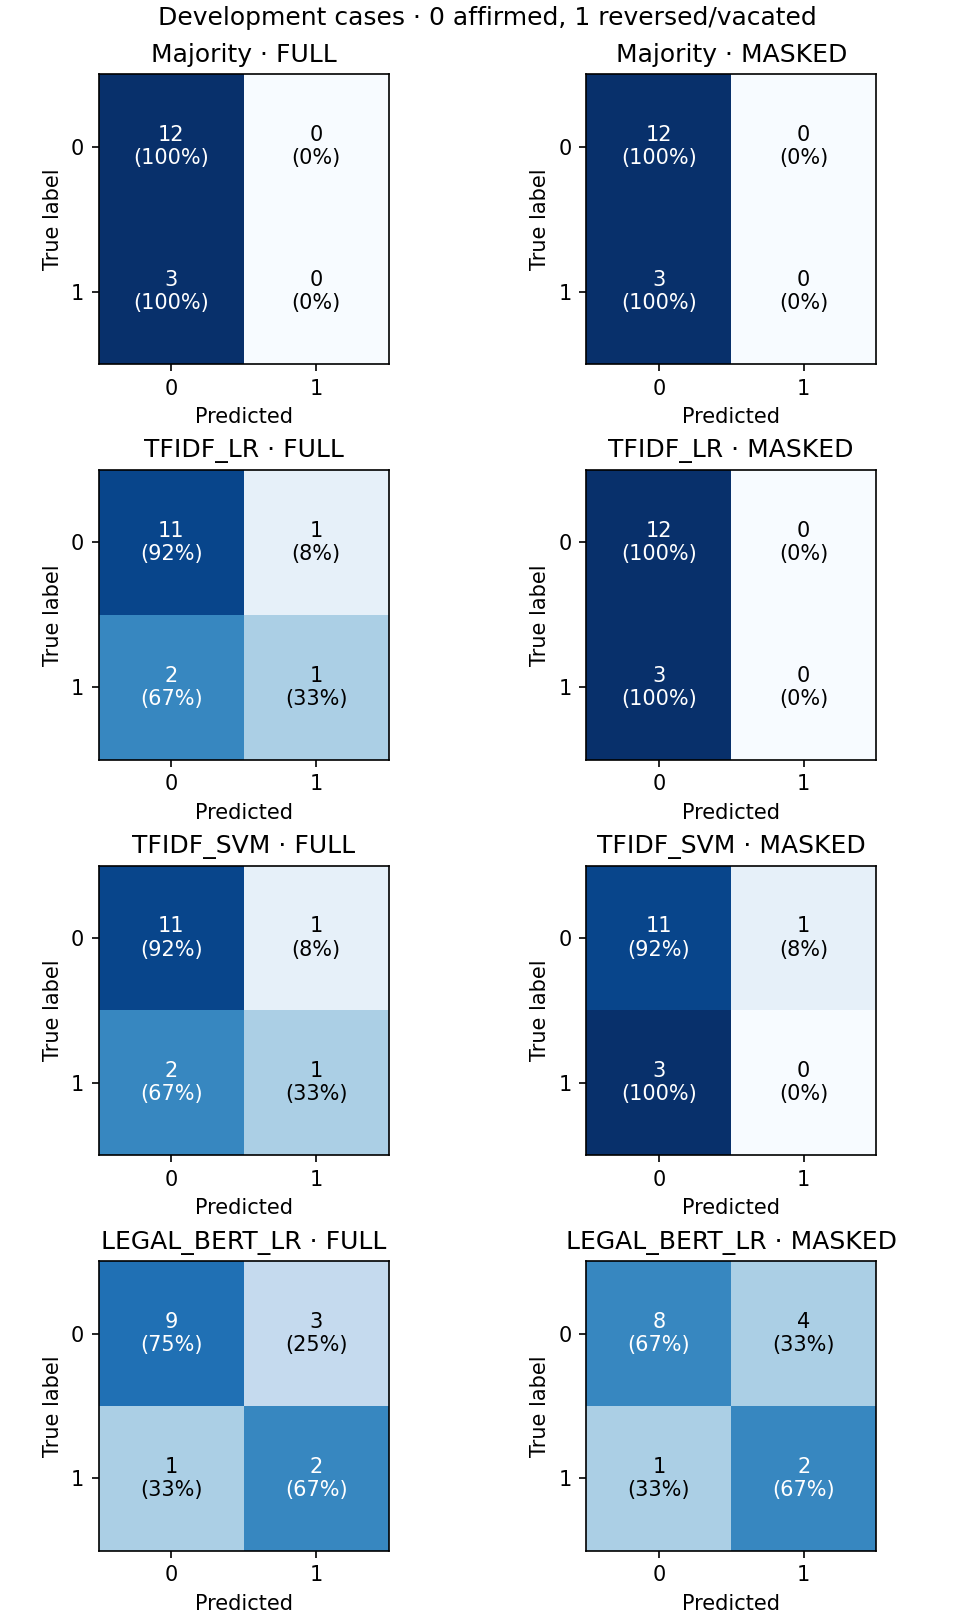

variant,FULL,MASKED,FULL minus MASKED
model,,,
LEGAL_BERT_LR,0.708333,0.666667,0.041667
Majority,0.500000,0.500000,0.000000
TFIDF_LR,0.625000,0.500000,0.125000
TFIDF_SVM,0.625000,0.458333,0.166667


In [3]:
results = pd.read_csv(RUN / 'results.csv')
display(results)
display(Image(filename=str(RUN / 'confusion_matrices.png')))
paired = results.pivot(index='model', columns='variant', values='balanced_accuracy')
paired['FULL minus MASKED'] = paired['FULL'] - paired['MASKED']
display(paired)

## Encoder and reproducibility

The encoder stays frozen in evaluation/inference mode. Every chunk contains up to 510 content tokens plus CLS/SEP. Pooling excludes specials and padding, and weights each chunk by content length.

In [4]:
display(run['encoder_settings'])
display(run['software'])
display(read('verification.json'))
display(read('length_summary.json'))

{'encoder': 'nlpaueb/legal-bert-base-uncased',
 'revision': '15b570cbf88259610b082a167dacc190124f60f6',
 'tokenizer': 'BertTokenizer',
 'use_fast': False,
 'content_tokens': 510,
 'overlap': 0,
 'padding_side': 'right',
 'batch_size_chunks': 4,
 'hidden_size': 768,
 'threads': 4,
 'pooling': 'last hidden layer; sum content-token vectors over all nonoverlapping chunks and divide by total content tokens; exclude special tokens and padding',
 'protocol_version': 1}

{'numpy': '2.3.4',
 'scipy': '1.16.3',
 'scikit-learn': '1.7.2',
 'matplotlib': '3.10.7',
 'torch': '2.9.1',
 'transformers': '4.57.1',
 'tokenizers': '0.22.2',
 'huggingface-hub': '0.36.2',
 'pandas': '2.3.3',
 'nbformat': '5.10.4',
 'nbclient': '0.10.2',
 'ipykernel': '6.30.1'}

{'reference_lexical_results': {'Majority': {'predictions_and_cv_identical': True,
   'maximum_decision_score_difference': 0},
  'TFIDF_LR': {'predictions_and_cv_identical': True,
   'maximum_decision_score_difference': 3.6637359812630166e-15},
  'TFIDF_SVM': {'predictions_and_cv_identical': True,
   'maximum_decision_score_difference': 6.106226635438361e-16}},
 'saved_folds_reused': True,
 'encoder_frozen': True,
 'content_tokens_per_chunk': 510,
 'tokenizer': {'class': 'BertTokenizer',
  'do_lower_case': True,
  'vocab_size': 30522,
  'padding_side': 'right',
  'cls_token_id': 101,
  'sep_token_id': 102,
  'pad_token_id': 0},
 'checkpoint_files_sha256': {'config.json': '716ea70c3c3e74bfe8496cc04cba7cd52f4ca45401e74042bb1058fe0390a1b6',
  'vocab.txt': '3aaa02f2e3a397eee0f813caa567c87cddab1045a4a6b8ac6261f0cc799efb8f',
  'pytorch_model.bin': '6b4f1da798ff101a66ad5cb11c6daa7f99cd41e7909277e01398576e8bd789bd'},
 'supplied_length_counts_match': True,
 'length_reference_sha256': 'dad57e3447

{'encoder': {'encoder': 'nlpaueb/legal-bert-base-uncased',
  'revision': '15b570cbf88259610b082a167dacc190124f60f6',
  'tokenizer': 'BertTokenizer',
  'use_fast': False,
  'content_tokens': 510,
  'overlap': 0,
  'padding_side': 'right',
  'batch_size_chunks': 4,
  'hidden_size': 768,
  'threads': 4,
  'pooling': 'last hidden layer; sum content-token vectors over all nonoverlapping chunks and divide by total content tokens; exclude special tokens and padding',
  'protocol_version': 1},
 'splits': {'train': {'cases': 97,
   'FULL': {'words': {'min': 107.0,
     'median': 476.0,
     'mean': 520.1958762886597,
     'p90': 820.2000000000003,
     'max': 1236.0},
    'tokens': {'min': 126.0,
     'median': 665.0,
     'mean': 714.9896907216495,
     'p90': 1107.8,
     'max': 1642.0},
    'chunks': {'min': 1.0,
     'median': 2.0,
     'mean': 1.8865979381443299,
     'p90': 3.0,
     'max': 4.0},
    'fraction_over_one_input': 0.7216494845360825,
    'total_chunks': 183},
   'MASKED': {'w

## Verify saved predictions and vectors

In [5]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
pred = pd.read_csv(RUN / 'predictions.csv')
expected = splits.loc[splits.period=='validation'].set_index('case_id')['label'].to_dict()
for _, result in results.iterrows():
    p = pred[(pred.model==result.model) & (pred.variant==result.variant)]
    assert len(p)==len(expected) and p.set_index('case_id')['label'].to_dict()==expected
    for key, value in [('accuracy',accuracy_score(p.label,p.prediction)),('balanced_accuracy',balanced_accuracy_score(p.label,p.prediction)),('macro_f1',f1_score(p.label,p.prediction,labels=[0,1],average='macro'))]:
        assert np.isclose(result[key],value,rtol=0,atol=1e-12)
    cm = next(x['counts'] for x in read('confusion_matrices.json')['conditions'] if x['model']==result.model and x['variant']==result.variant)
    assert confusion_matrix(p.label,p.prediction,labels=[0,1]).tolist()==cm
index = read('embedding_index.json')
assert [r['case_id'] for r in index['rows']]==splits.case_id.tolist()
for name, checksum in index['files_sha256'].items():
    assert hashlib.sha256((RUN/name).read_bytes()).hexdigest()==checksum
    vectors = np.load(RUN/name,allow_pickle=False)
    assert vectors.shape==(len(splits),768) and np.isfinite(vectors).all()
print(f'Verified {len(results)} conditions on {len(expected)} shared evaluation cases and both embedding matrices.')

Verified 8 conditions on 15 shared evaluation cases and both embedding matrices.
